In [6]:
!pip install -q scikit-learn optuna openpyxl

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, ConfusionMatrixDisplay, f1_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
np.random.seed(SEED)

In [7]:
excel_path = "/kaggle/input/datasets/trnvnsn/flood-data/Pluvial_Flood_Dataset.xlsx"

df_full = pd.read_excel(excel_path, engine='openpyxl')
df_full.columns = df_full.columns.str.strip()
feature_names = [col for col in df_full.columns if col != 'SUSCEP']

# Chuyển NoData GIS thành NaN để imputer xử lý như base.
X = df_full[feature_names].apply(pd.to_numeric, errors='raise')
X = X.replace([np.inf, -np.inf, -9999], np.nan).mask(lambda values: values <= -1e30).values
label_map = {'No_Flood': 0, 'Low': 1, 'Moderate': 1, 'High': 1, 'Very_High': 1}
y = df_full['SUSCEP'].str.strip().map(label_map)
if y.isna().any():
    raise ValueError('SUSCEP chứa nhãn thiếu hoặc không thuộc label_map.')
y = y.values.astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# Tuning dùng validation cố định; train cuối dùng lại toàn bộ X_train.
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train, y_train, test_size=0.25, random_state=SEED, stratify=y_train
)

print(f"Tuning Train: {X_fit.shape} | Validation: {X_valid.shape} | Test: {X_test.shape}")

Tuning Train: (86640, 9) | Validation: (28880, 9) | Test: (28881, 9)


In [8]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 400, step=50),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 5),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
        'class_weight': trial.suggest_categorical('class_weight', ['balanced', 'balanced_subsample']),
        'random_state': SEED,
        'n_jobs': -1
    }
    
    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', RandomForestClassifier(**params))
    ])
    
    pipeline.fit(X_fit, y_fit)
    y_valid_pred = pipeline.predict(X_valid)
    return f1_score(y_valid, y_valid_pred, average='macro')

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=10)

print(f"Best Validation F1-Macro : {study.best_value:.4f}")
print(f"Best Parameters  : {study.best_params}")

Best Validation F1-Macro : 1.0000
Best Parameters  : {'n_estimators': 200, 'max_depth': 10, 'min_samples_split': 8, 'min_samples_leaf': 3, 'max_features': 'sqrt', 'class_weight': 'balanced'}


KẾT QUẢ ĐỘC LẬP TRÊN TẬP TEST:
                     precision    recall  f1-score   support

       No_Flood (0)     1.0000    1.0000    1.0000      3225
Có nguy cơ ngập (1)     1.0000    1.0000    1.0000     25656

           accuracy                         1.0000     28881
          macro avg     1.0000    1.0000    1.0000     28881
       weighted avg     1.0000    1.0000    1.0000     28881

Test ROC-AUC Score: 1.0000


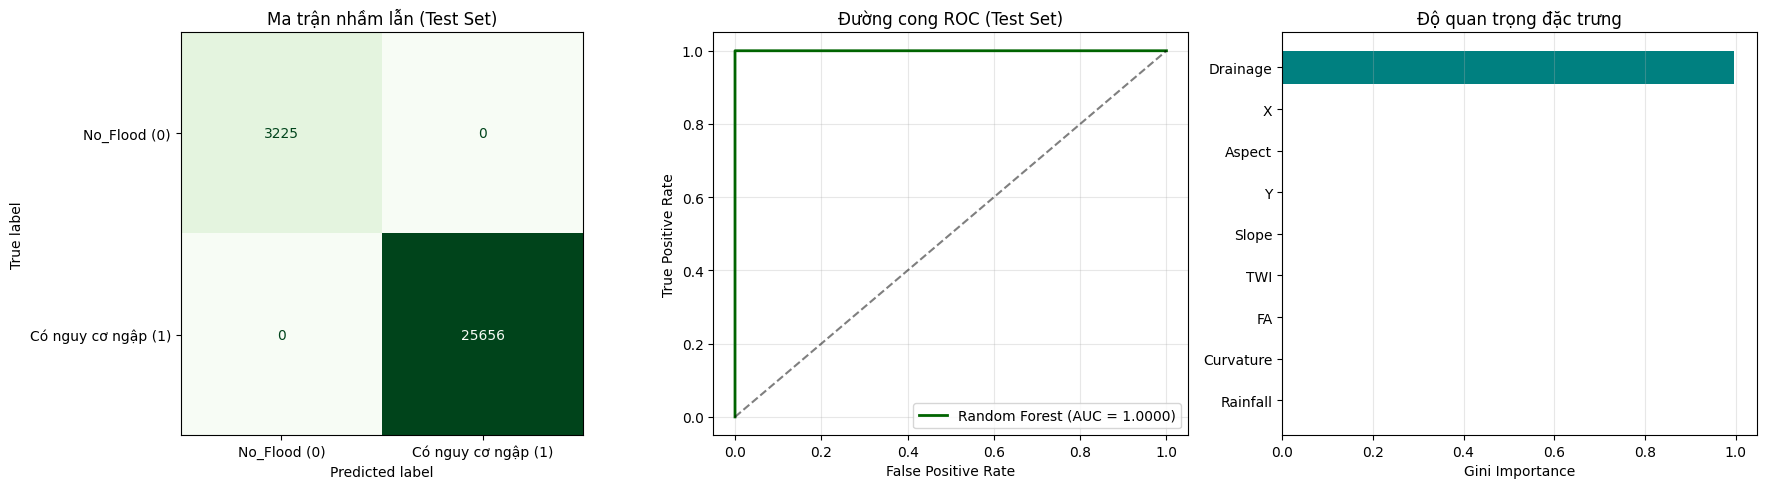

In [9]:
best_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', RandomForestClassifier(**study.best_params, random_state=SEED, n_jobs=-1))
])

best_pipeline.fit(X_train, y_train)

y_pred = best_pipeline.predict(X_test)
y_prob = best_pipeline.predict_proba(X_test)[:, 1]

print("=" * 60)
print("KẾT QUẢ ĐỘC LẬP TRÊN TẬP TEST:")
print("=" * 60)
print(classification_report(y_test, y_pred, target_names=['No_Flood (0)', 'Có nguy cơ ngập (1)'], digits=4))
print(f"Test ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['No_Flood (0)', 'Có nguy cơ ngập (1)'],
    cmap='Greens', ax=axes[0], colorbar=False
)
axes[0].set_title('Ma trận nhầm lẫn (Test Set)')

fpr, tpr, _ = roc_curve(y_test, y_prob)
auc_val = roc_auc_score(y_test, y_prob)
axes[1].plot(fpr, tpr, color='darkgreen', lw=2, label=f'Random Forest (AUC = {auc_val:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].set_title('Đường cong ROC (Test Set)')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3)

importances = best_pipeline.named_steps['classifier'].feature_importances_
sorted_idx = np.argsort(importances)
axes[2].barh(np.array(feature_names)[sorted_idx], importances[sorted_idx], color='teal')
axes[2].set_title('Độ quan trọng đặc trưng')
axes[2].set_xlabel('Gini Importance')
axes[2].grid(True, axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig("final_random_forest_evaluation.png", dpi=300)
plt.show()

In [10]:
model_filename = 'best_model.pkl'
joblib.dump(best_pipeline, model_filename)
print(f"Đã lưu Pipeline mô hình thành công: {model_filename}")

Đã lưu Pipeline mô hình thành công: best_model.pkl
